In [9]:
import os
import pandas as pd
import plotly.graph_objs as go
from openpyxl import load_workbook
from openpyxl.utils import column_index_from_string
import warnings
from pathlib import Path
import configparser
import re

warnings.filterwarnings("ignore")

# === CONFIG ===
base_path = r"C:\MyDocuments\03Business\05ResearchAndAnalysis\StockInvestments\QuarterResultsScreenerExcels"
ITLargeCapTickers = ['TCS', 'INFY', 'HCLTECH', 'WIPRO', 'LTIM', 'TECHM']  # Manually defined tickers
ITOtherTickers = ['PERSISTENT', 'KPIT', 'MPHASIS', 'COFORGE', 'CYIENT']
LifeInsurancesTickers = ['HDFCLIFE', 'SBILIFE', 'ICICIPRULI']
LargeCapBanksTickers = ['HDFCBANK', 'ICICIBANK', 'AXISBANK']
GeneralInsuranceTickers = ['ICICIGI']
CustomTickers = ['HCLTECH']

tickers = CustomTickers

# === Get folders like 2025Q1, 2025Q2 ===
def get_available_quarters(base_path):
    pattern = re.compile(r"^\d{4}Q[1-4]$")
    return sorted([
        f.name for f in Path(base_path).iterdir()
        if f.is_dir() and pattern.match(f.name)
    ], reverse=True)

# === Find latest file for each ticker ===
def find_latest_quarter_files(base_path, tickers):
    folders = get_available_quarters(base_path)
    quarter_map = {}
    for ticker in tickers:
        for quarter in folders:
            fy_suffix = quarter[:4][-2:] + quarter[-2:]
            file_name = f"{ticker}_FY{fy_suffix}.xlsx"
            file_path = os.path.join(base_path, quarter, file_name)
            if os.path.exists(file_path):
                quarter_map[ticker] = quarter
                break
    return quarter_map

# === Detect latest files ===
ticker_quarter_map = find_latest_quarter_files(base_path, tickers)
tickers = list(ticker_quarter_map.keys())
latestQuarters = list(ticker_quarter_map.values())

# === Load files fully (pandas + openpyxl) ===
file_cache = {}
for ticker, quarter in zip(tickers, latestQuarters):
    fy_suffix = quarter[:4][-2:] + quarter[-2:]
    file_name = f"{ticker}_FY{fy_suffix}.xlsx"
    file_path = os.path.join(base_path, quarter, file_name)

    try:
        xl_pd = pd.read_excel(file_path, sheet_name=None, header=None)
        xl_wb = load_workbook(file_path, data_only=True)
        file_cache[ticker] = {
            "path": file_path,
            "quarter": quarter,
            "sheets_pd": xl_pd,
            "workbook": xl_wb
        }
    except Exception as e:
        print(f"Error loading {file_path}: {e}")

# Optional: show summary
for t in tickers:
    print(f"{t}: {ticker_quarter_map[t]}")

HCLTECH: 2025Q4


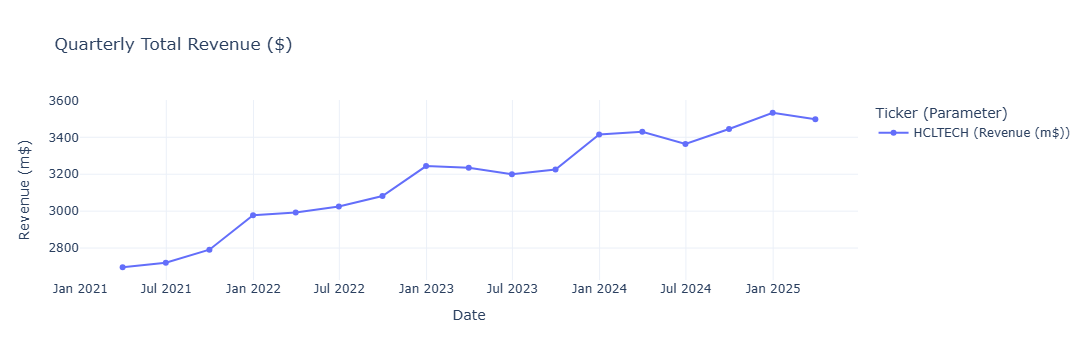

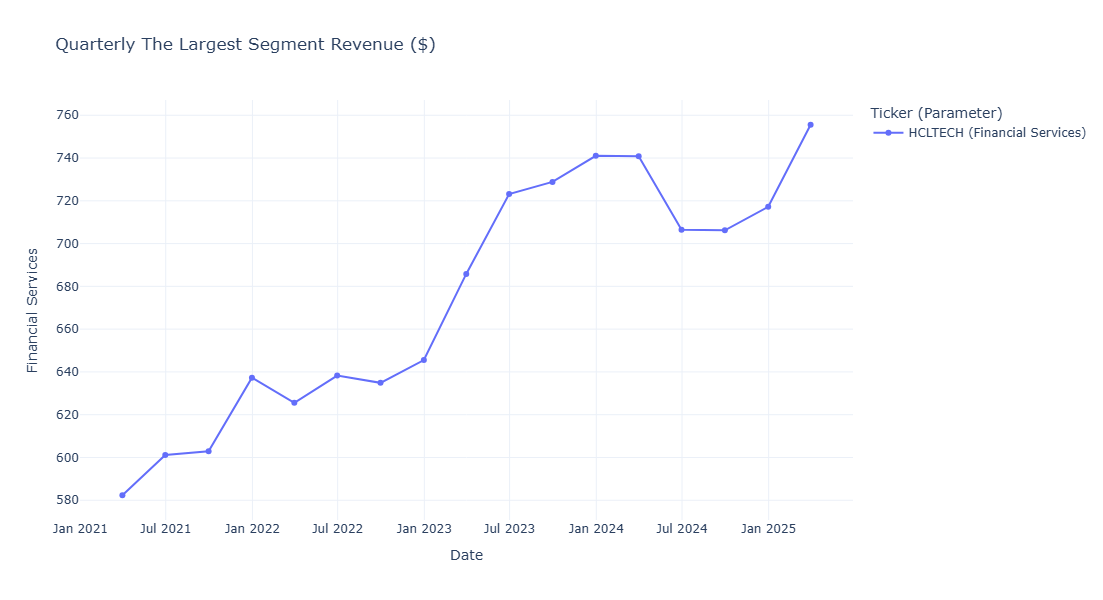

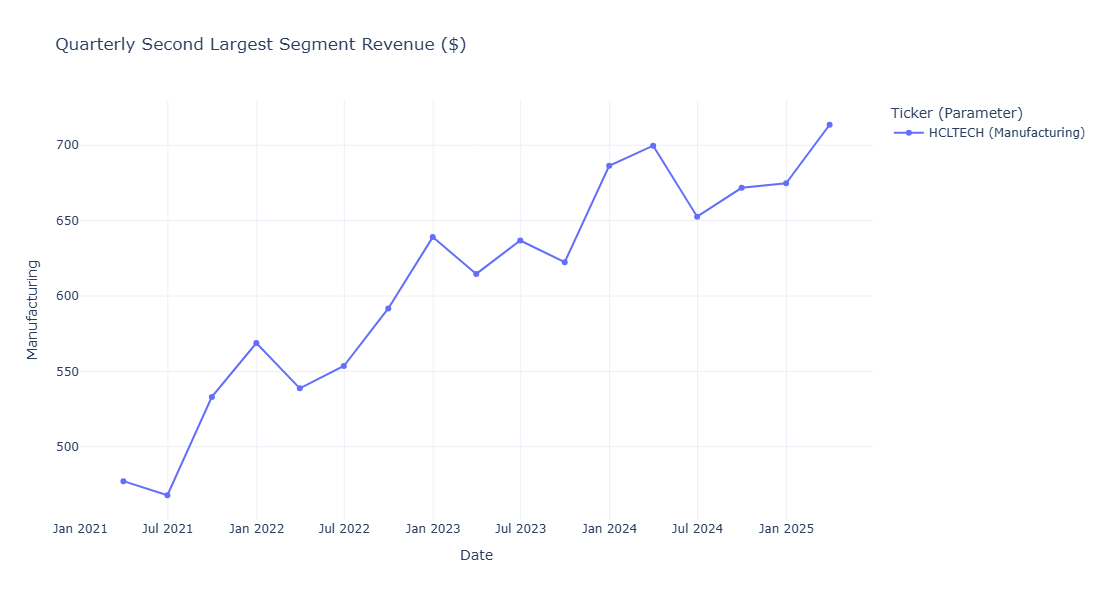

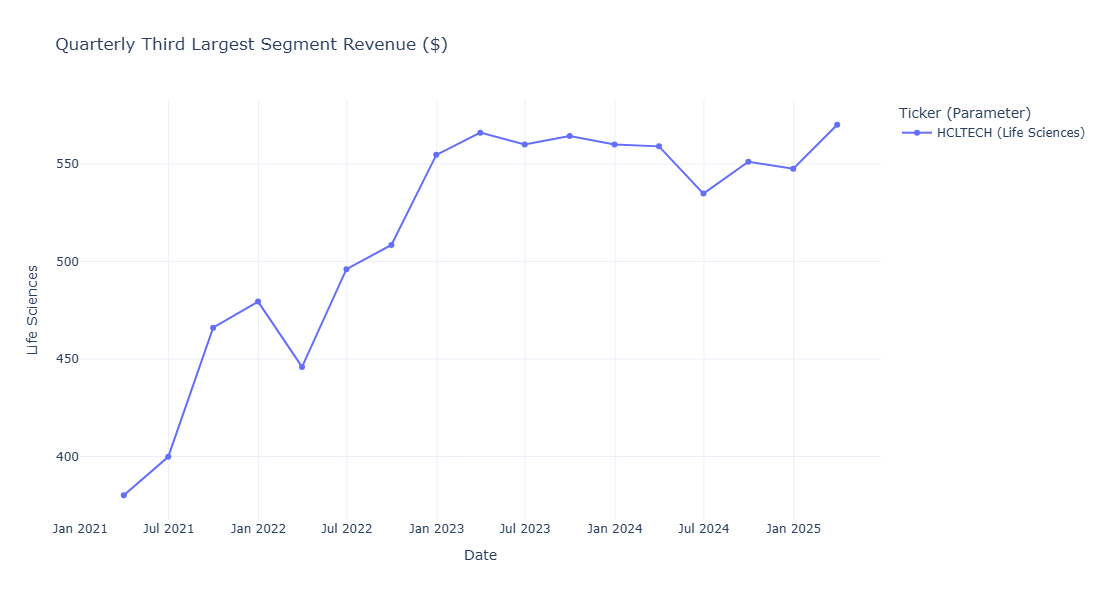

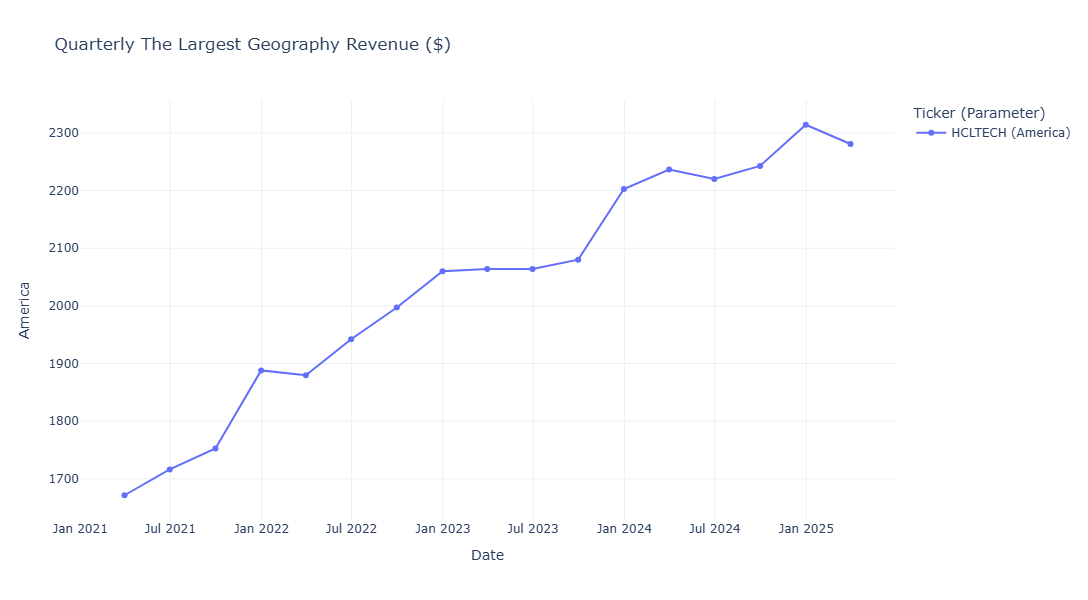

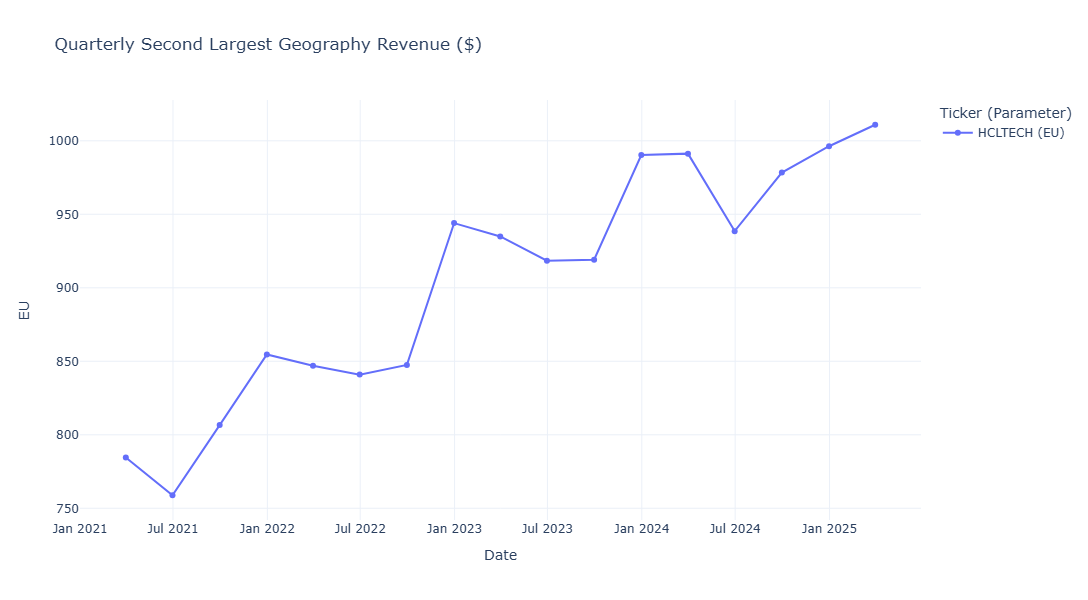

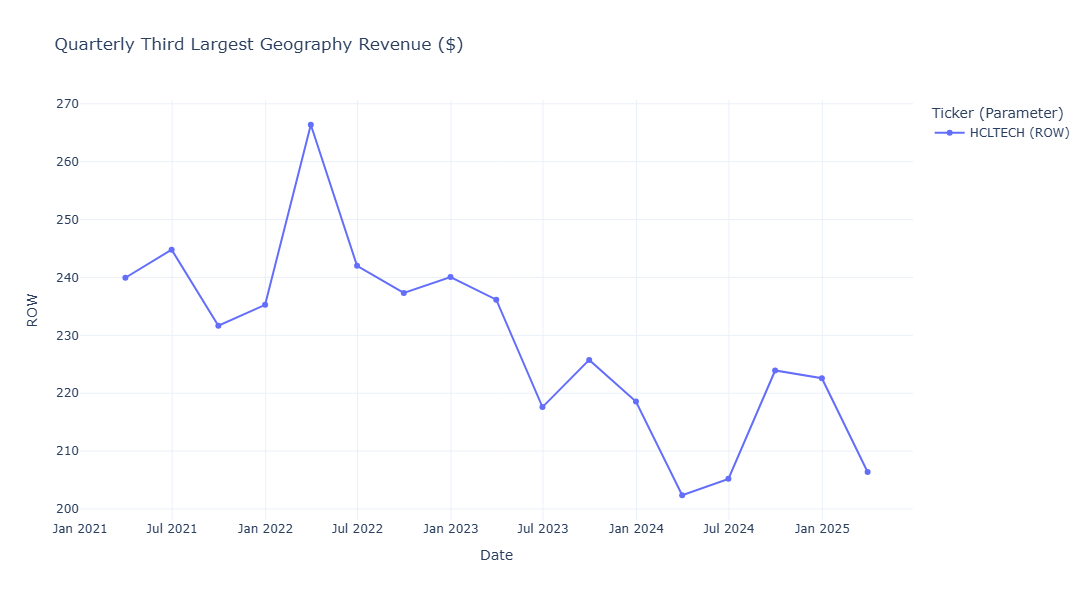

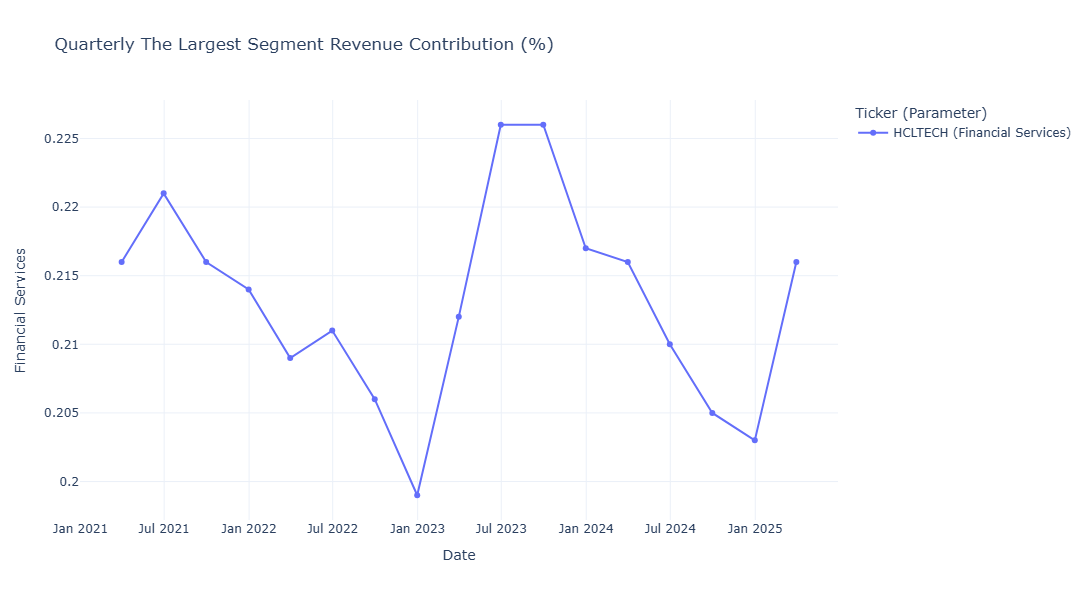

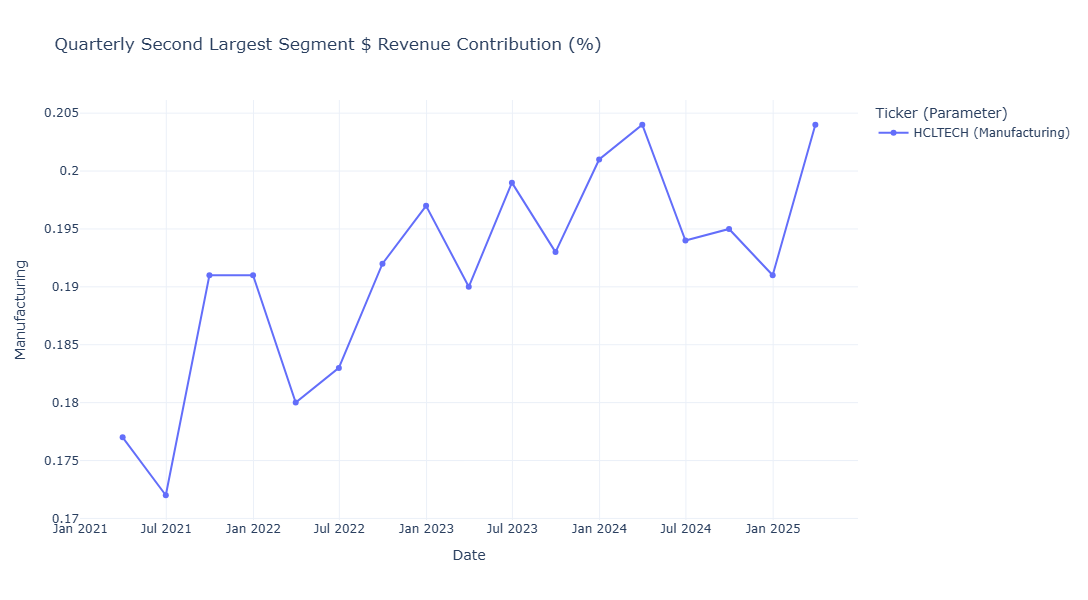

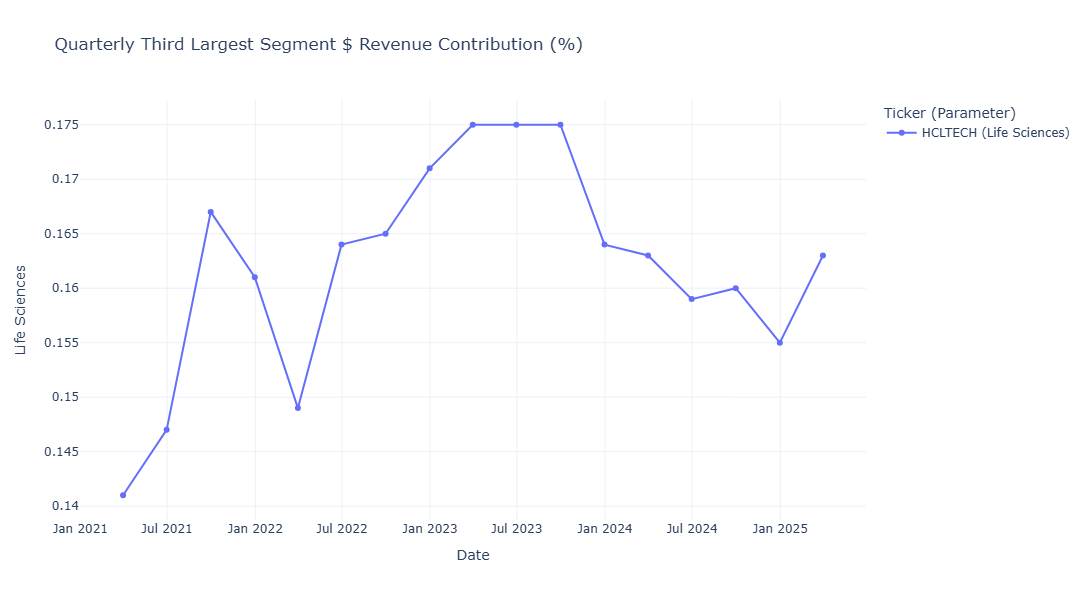

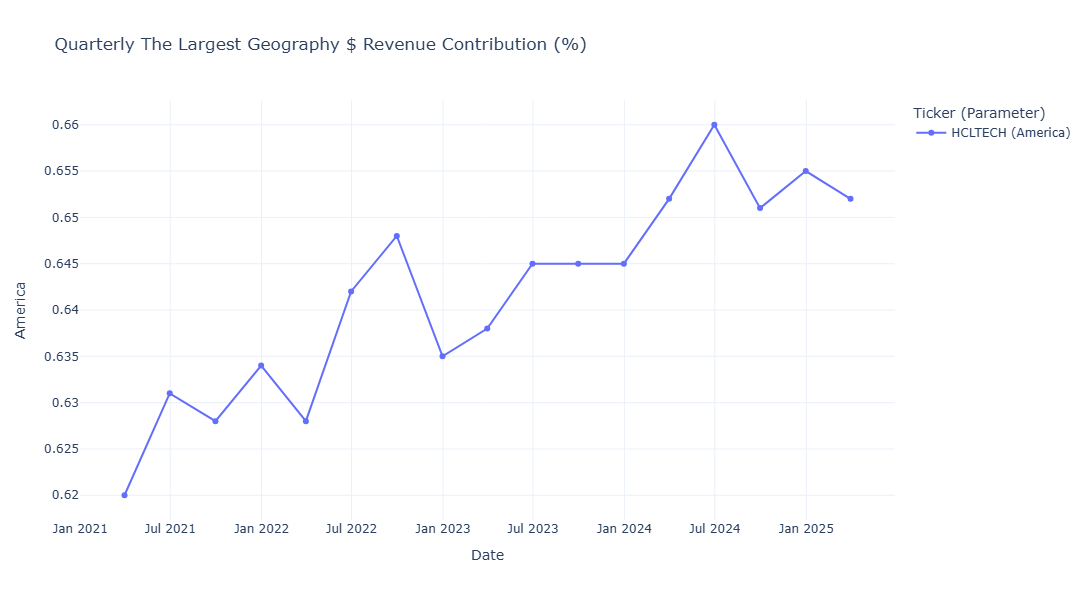

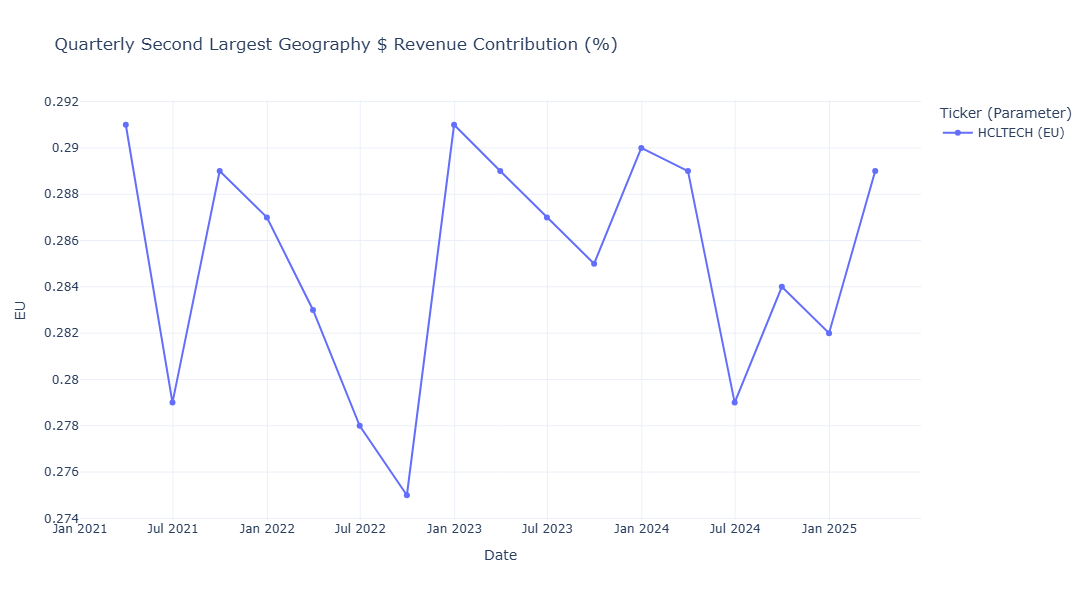

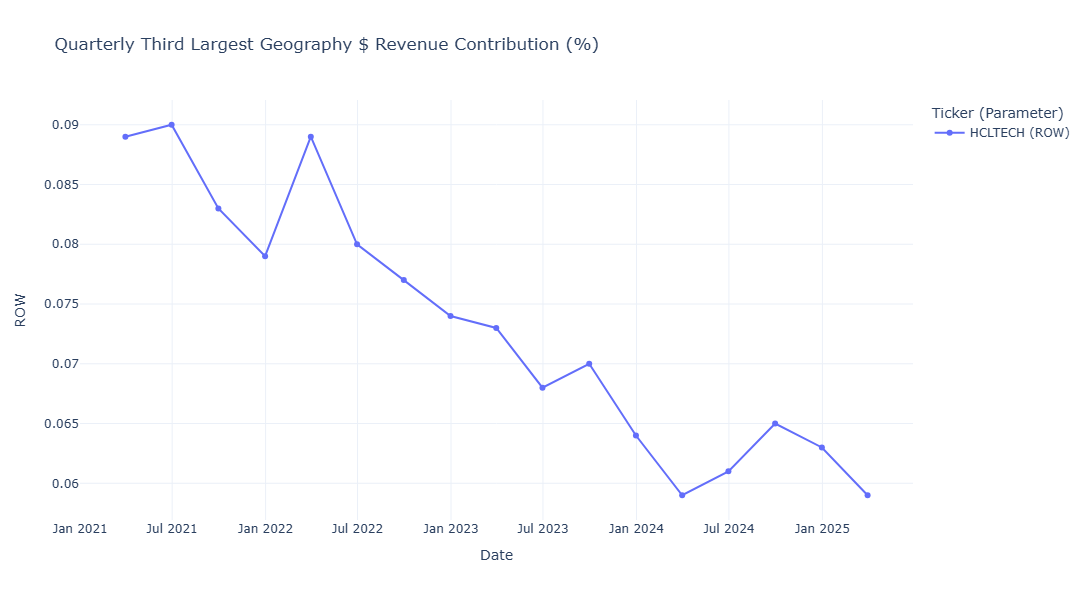

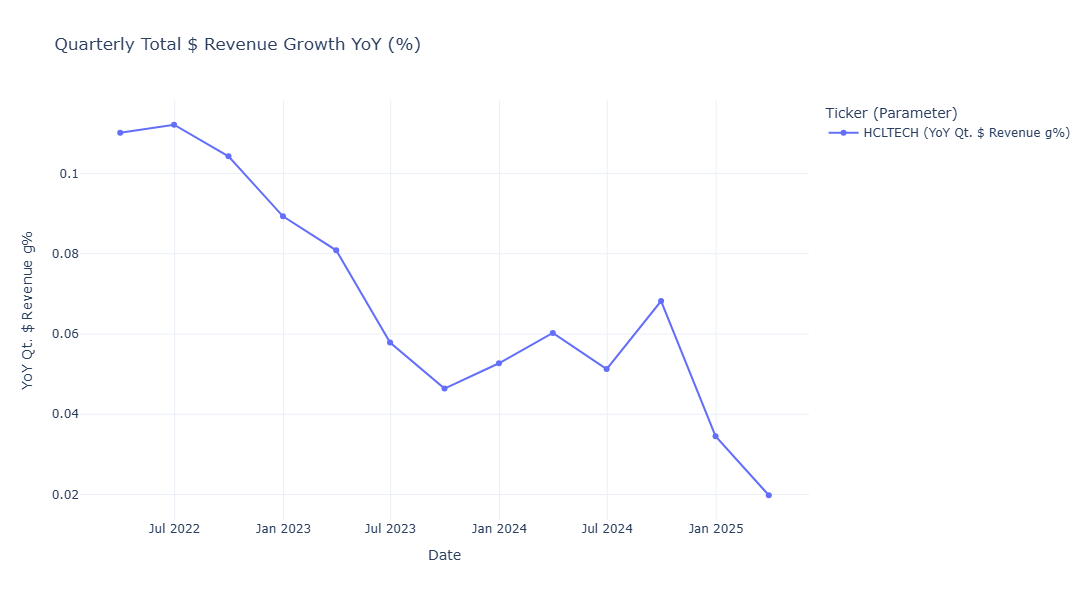

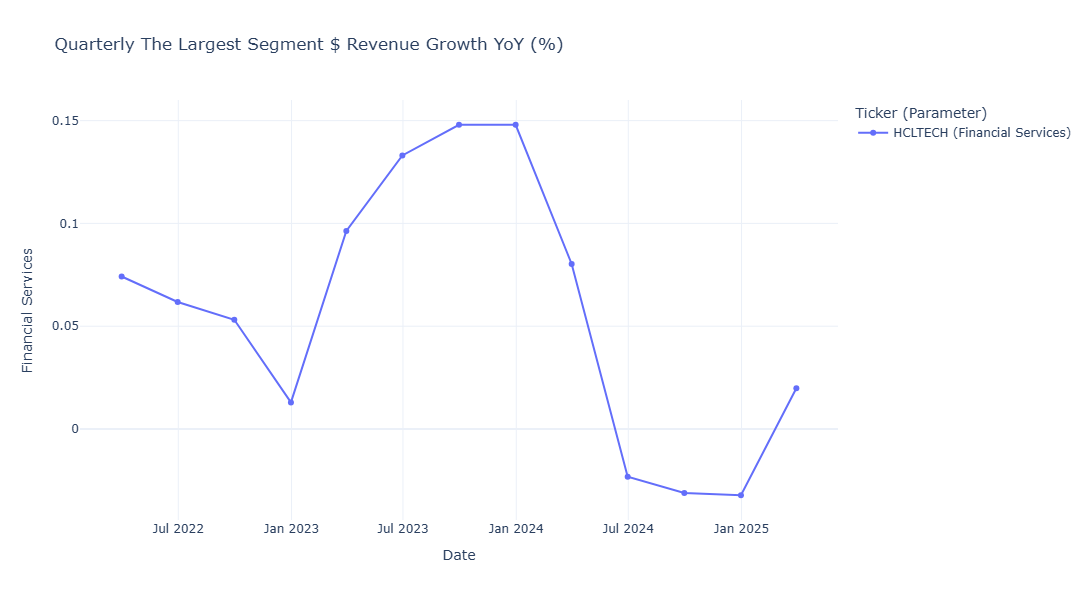

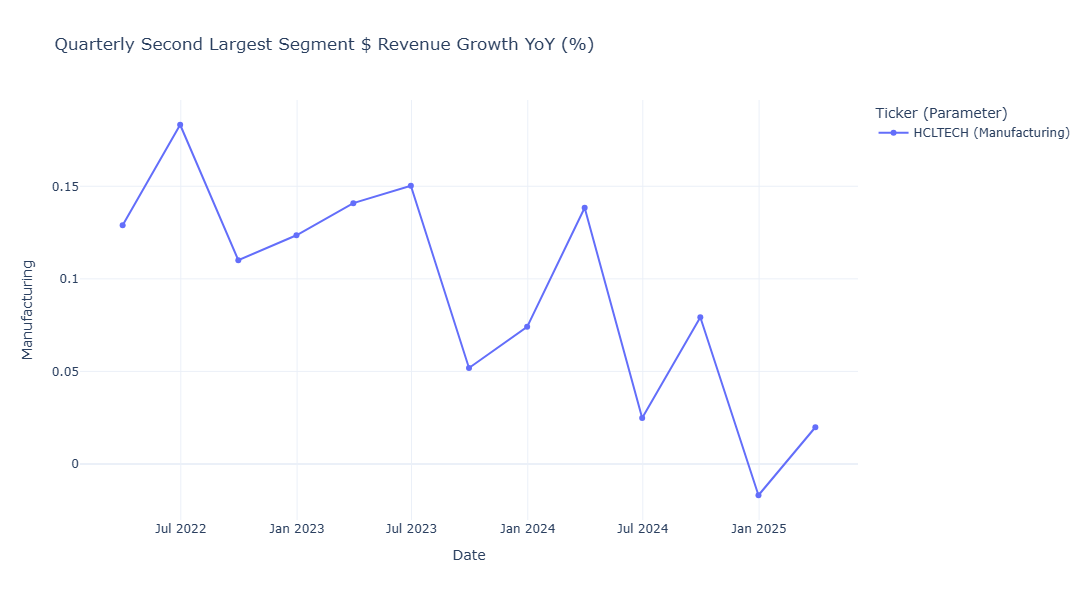

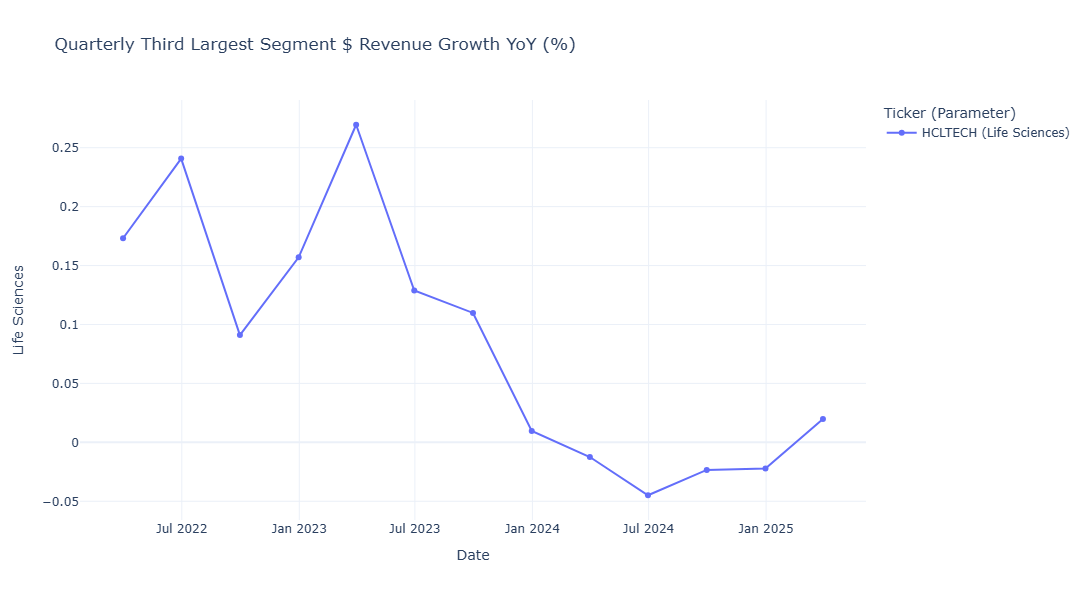

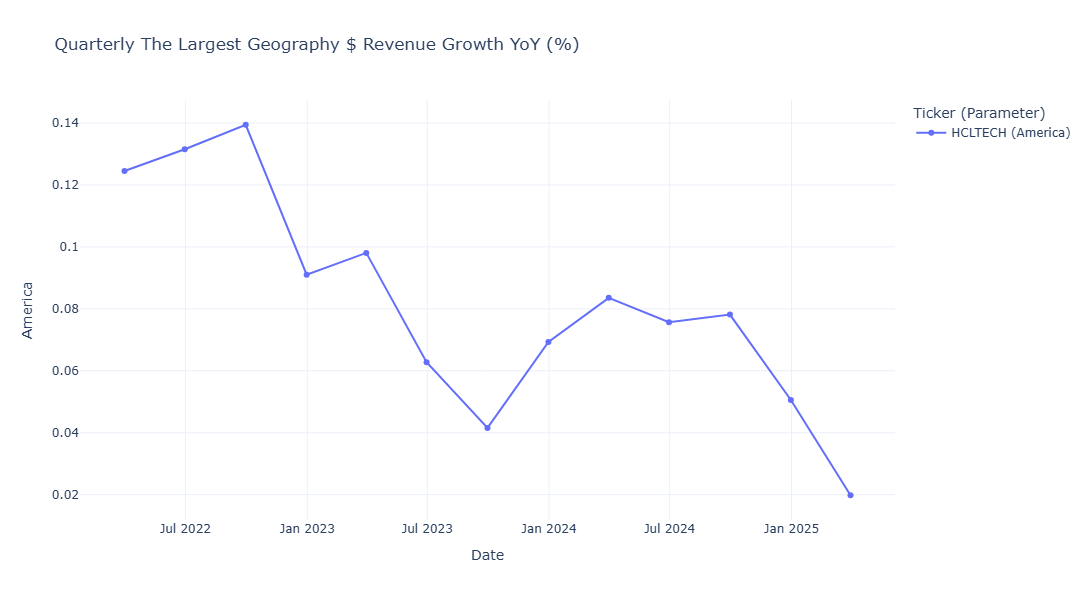

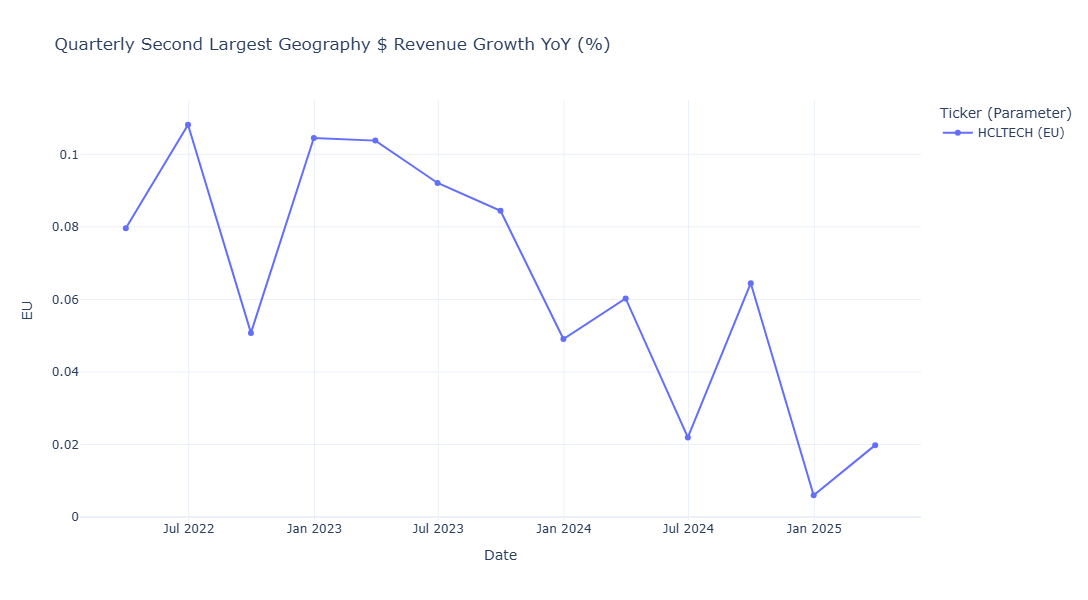

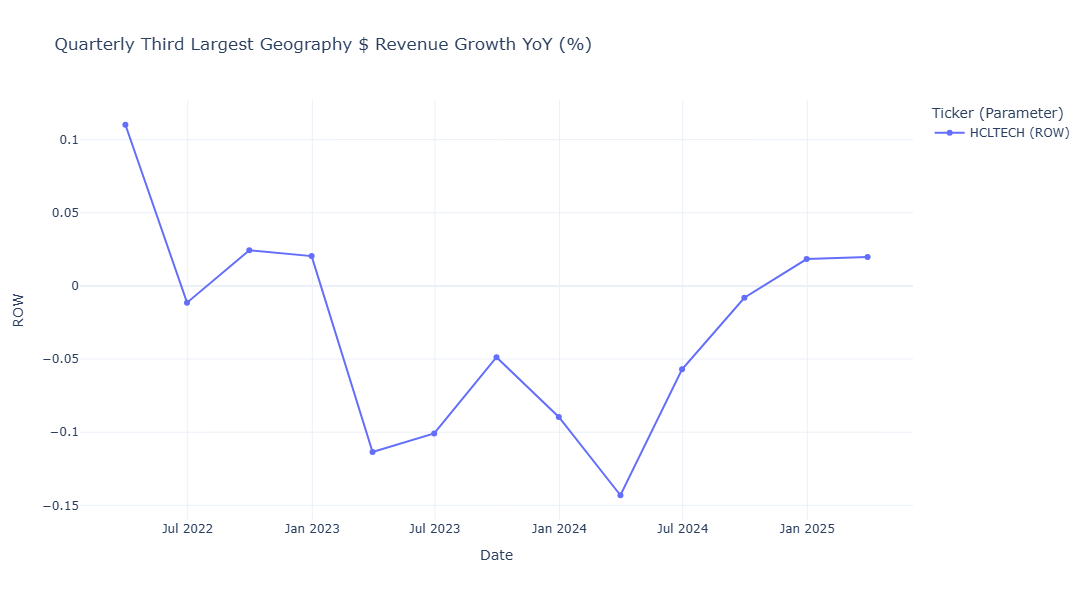

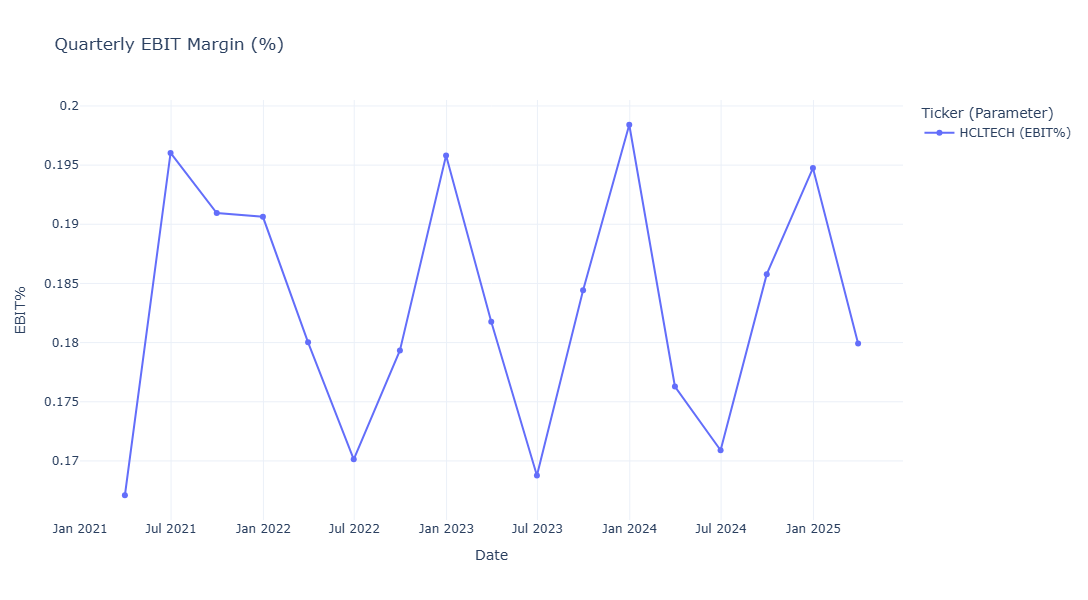

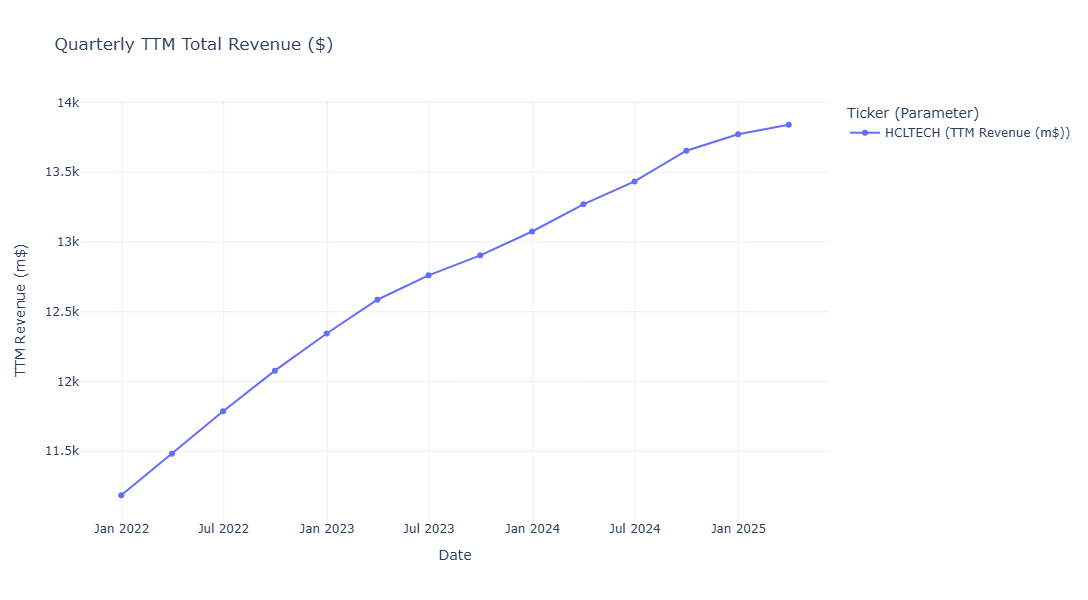

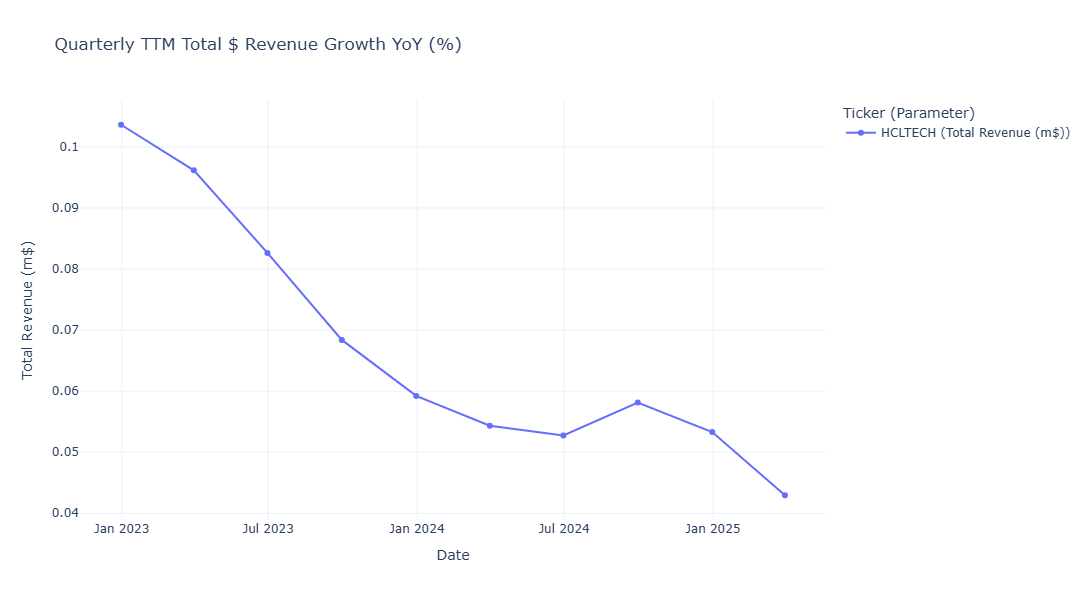

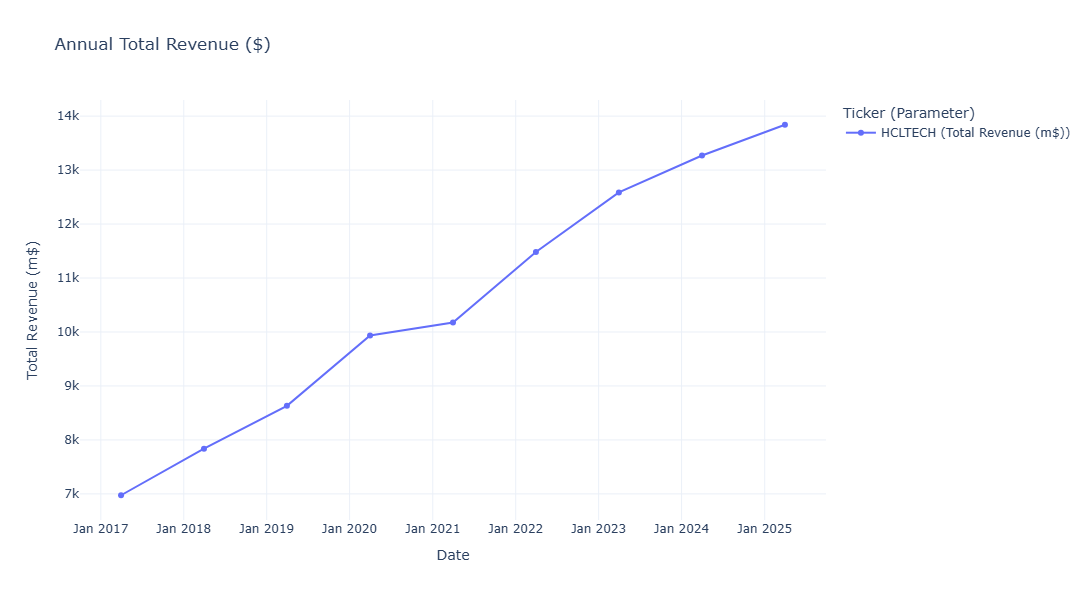

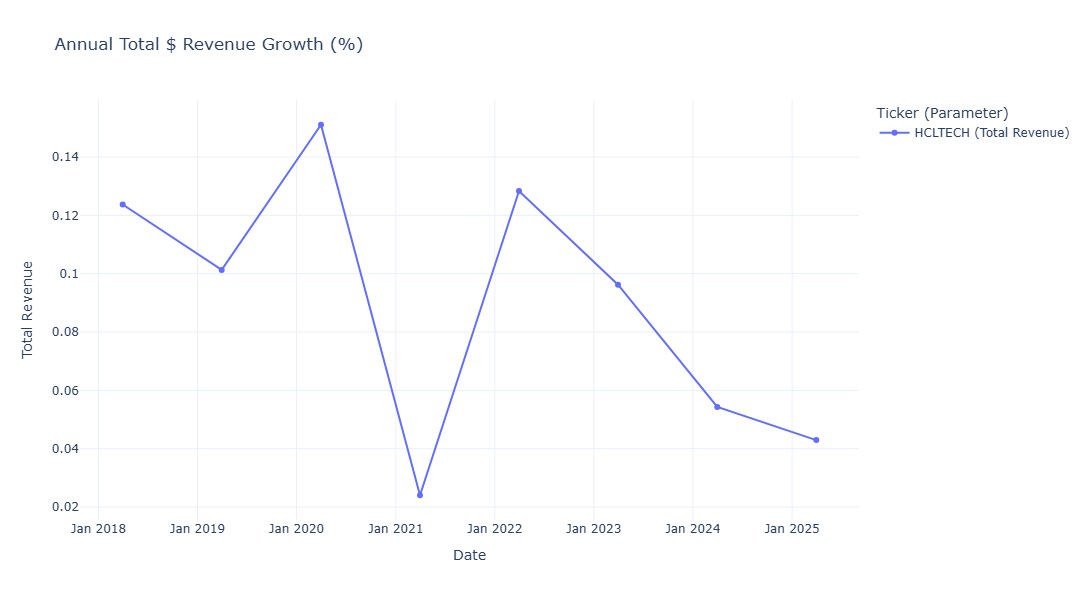

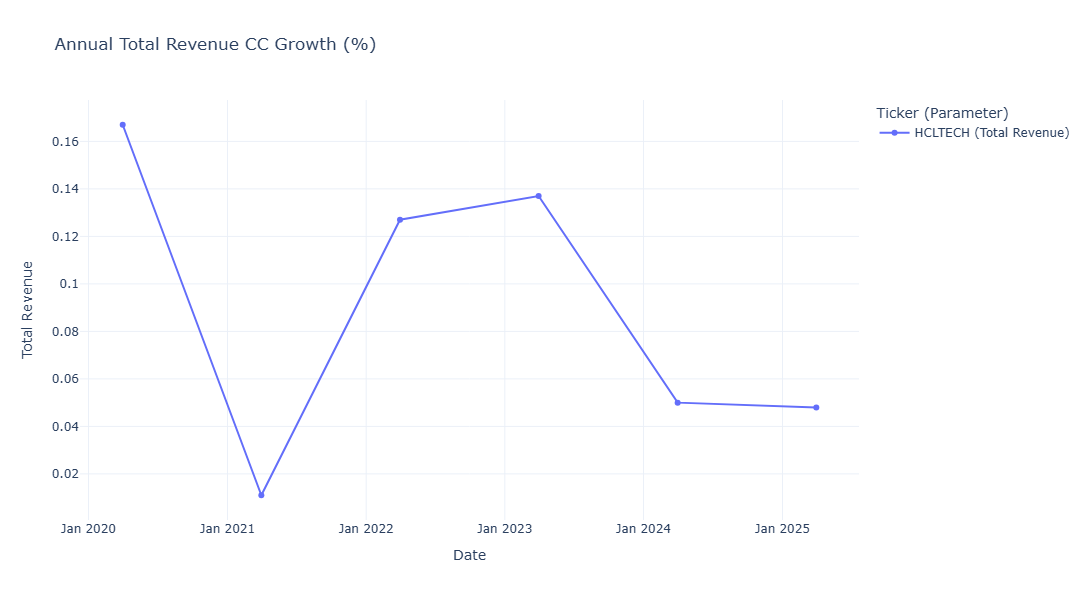

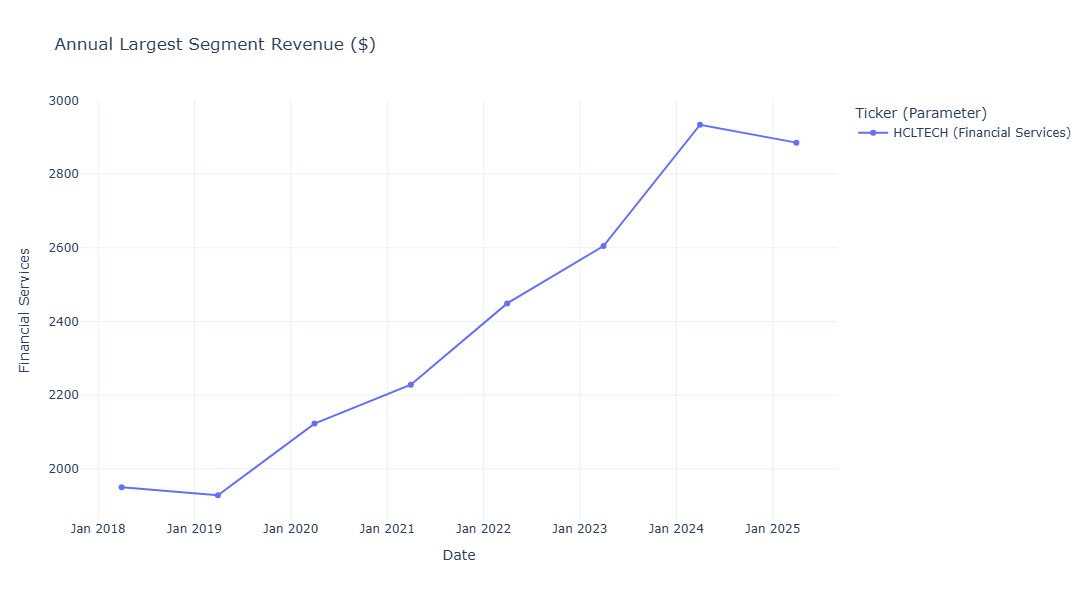

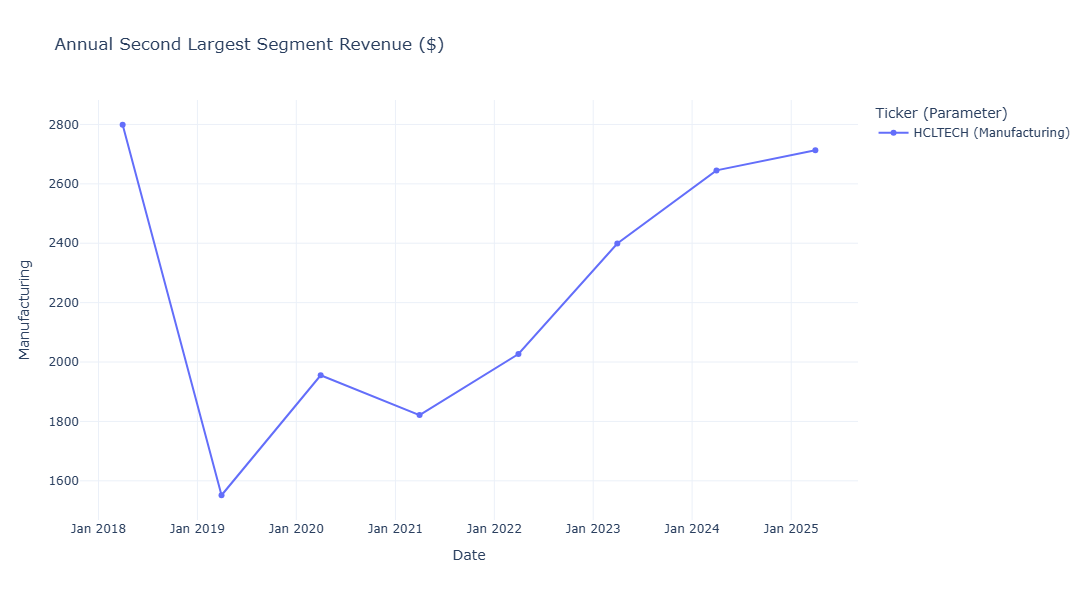

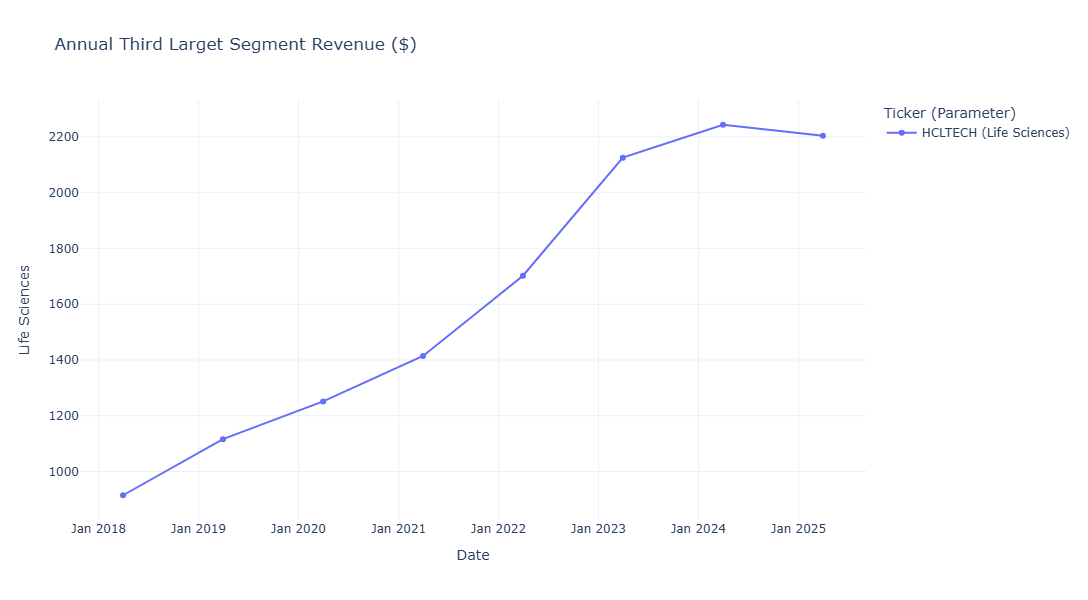

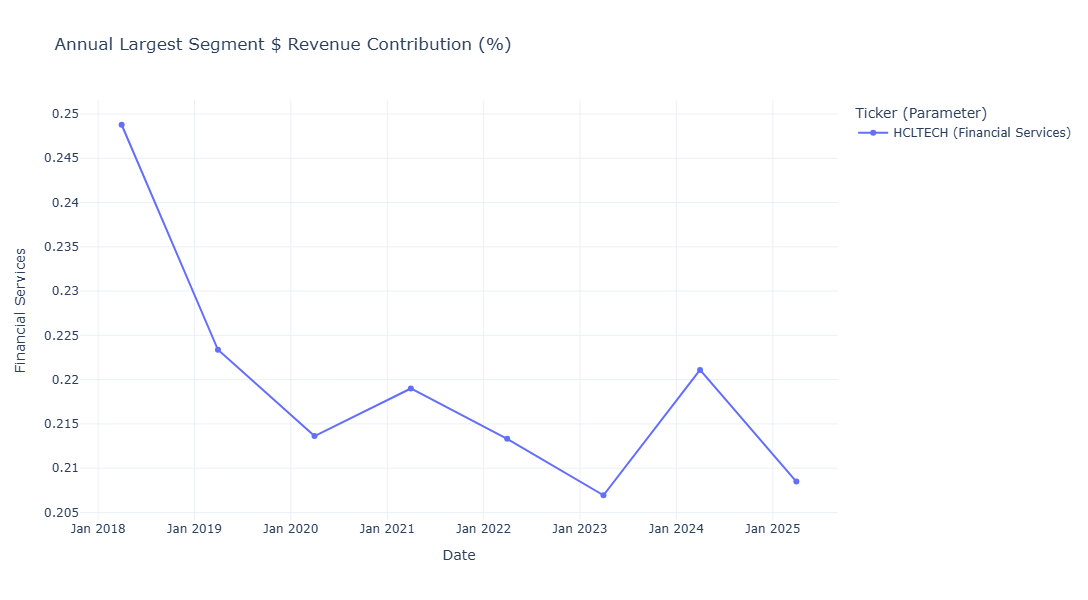

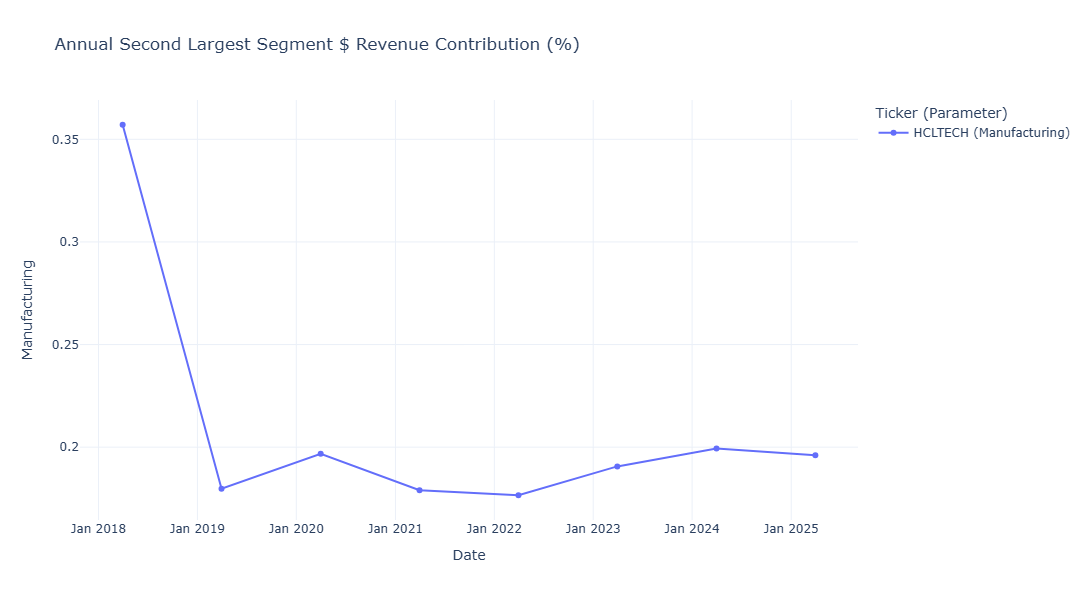

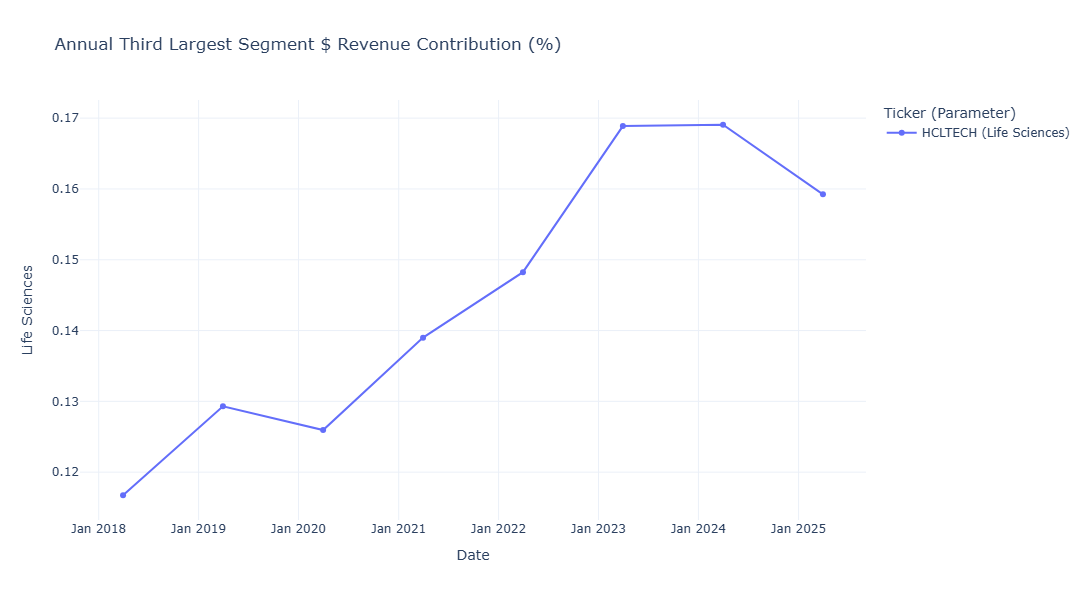

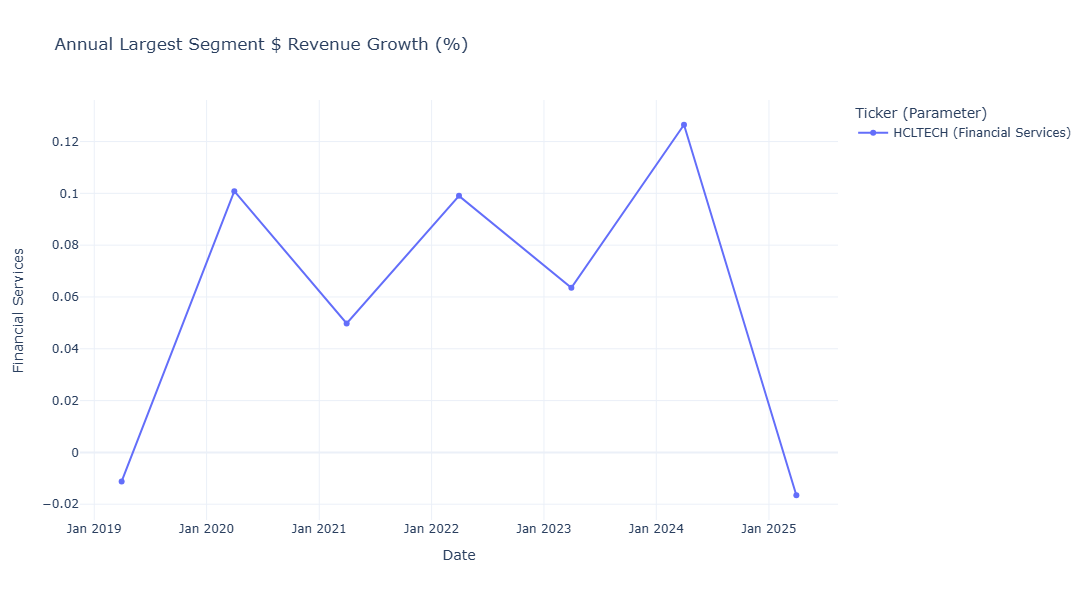

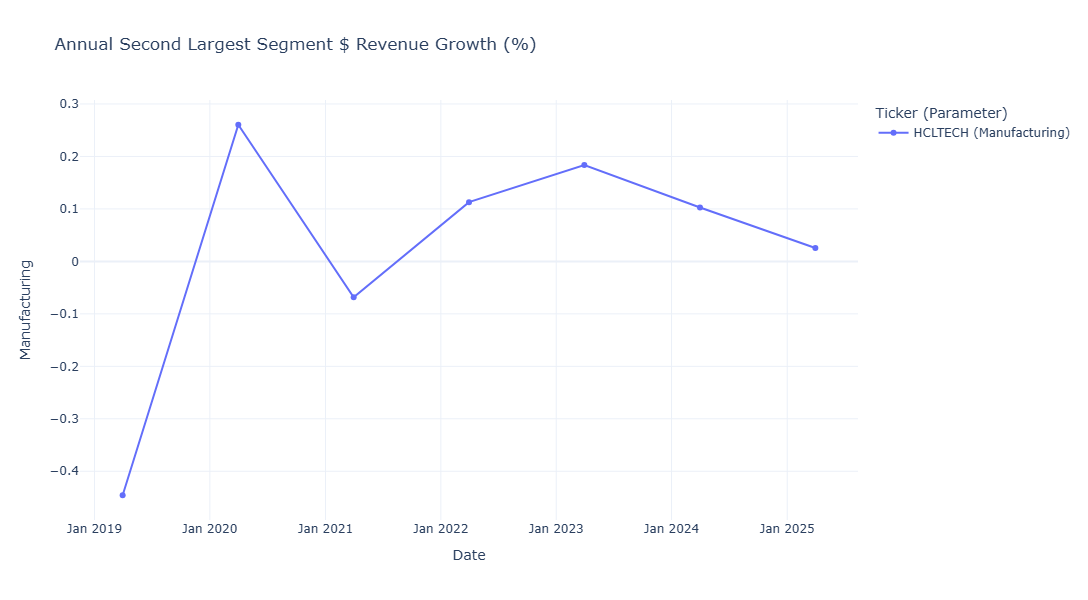

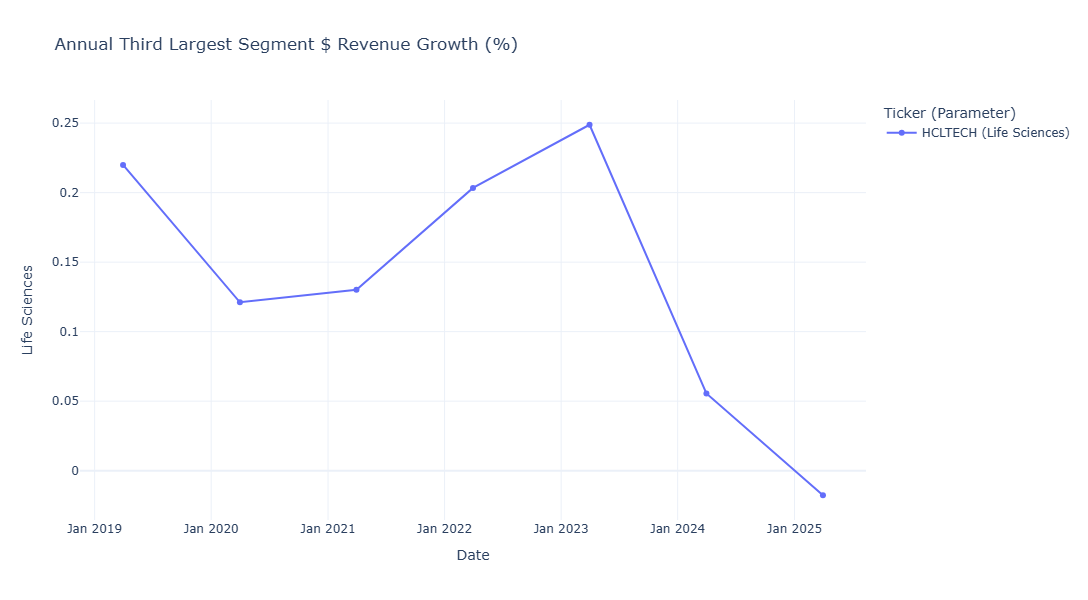

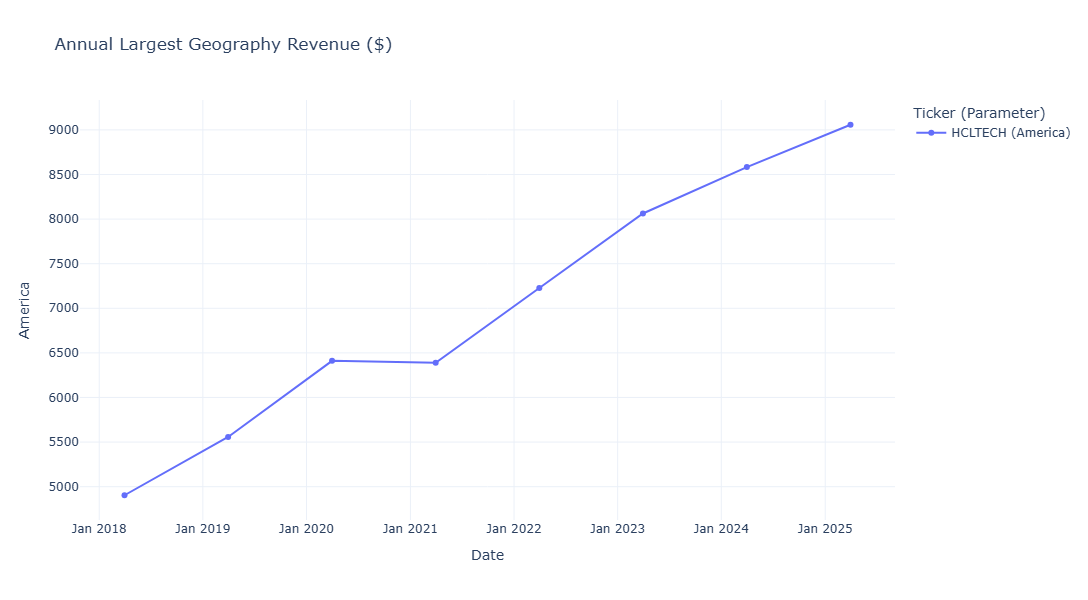

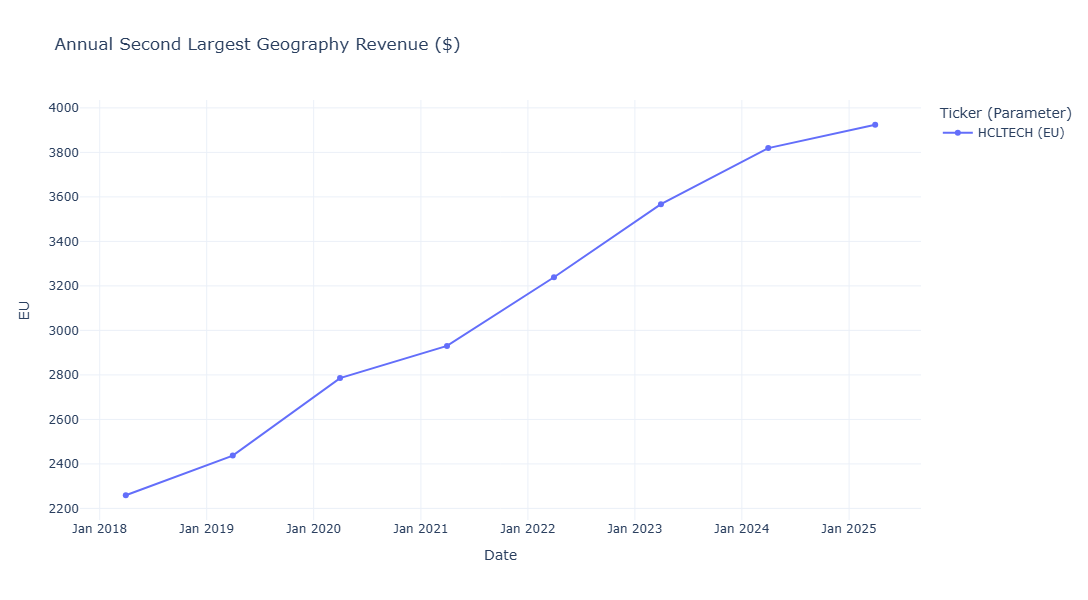

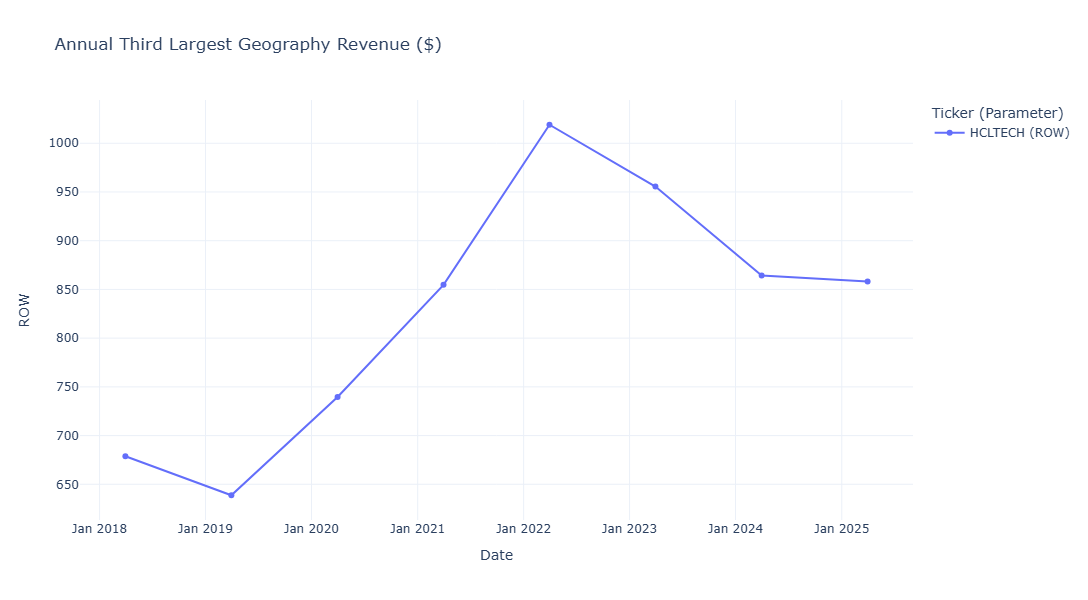

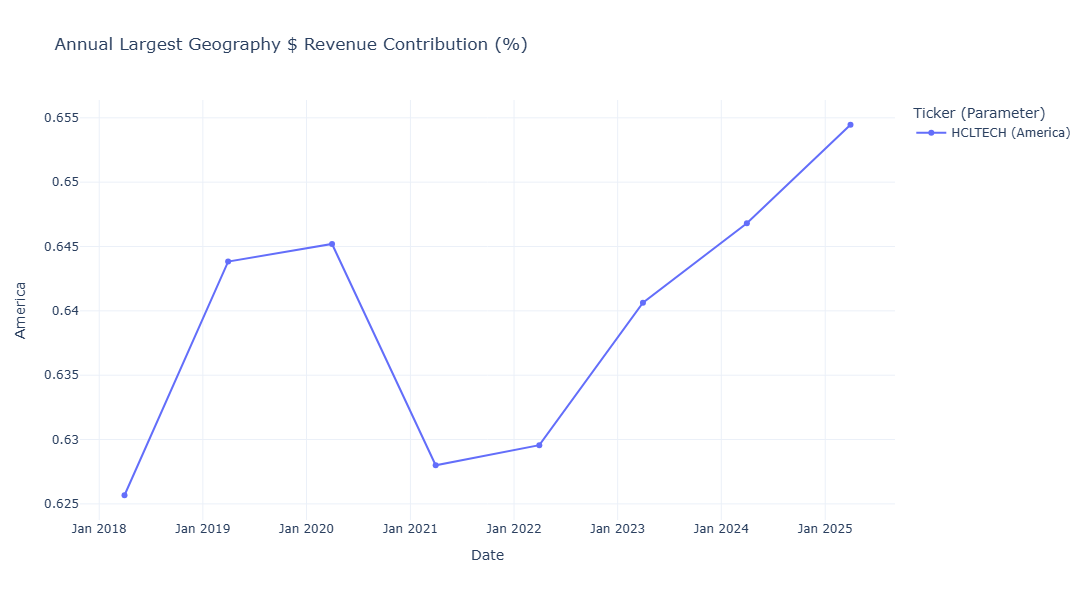

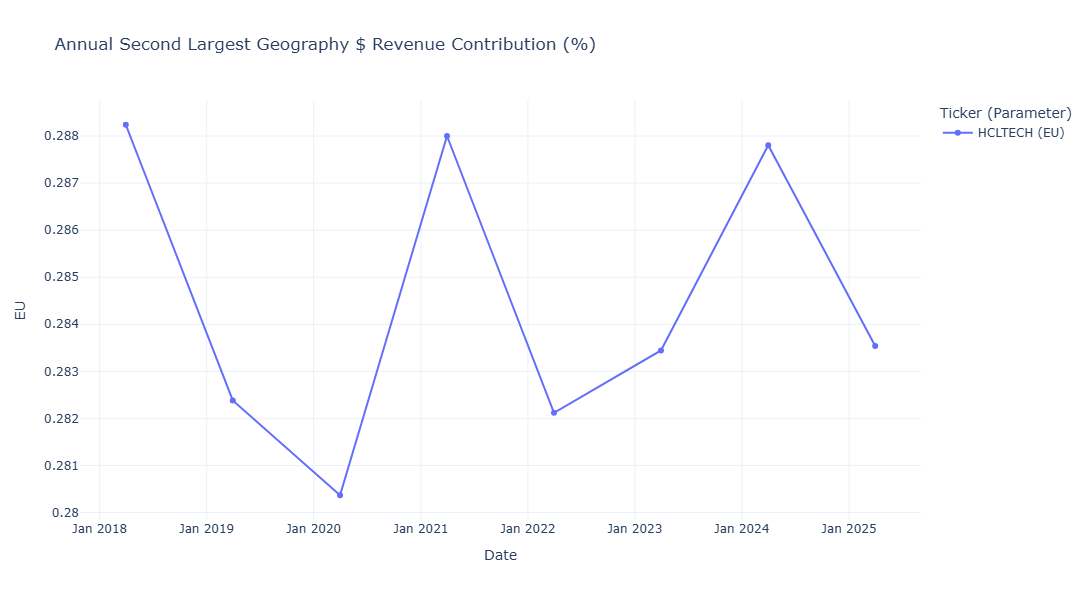

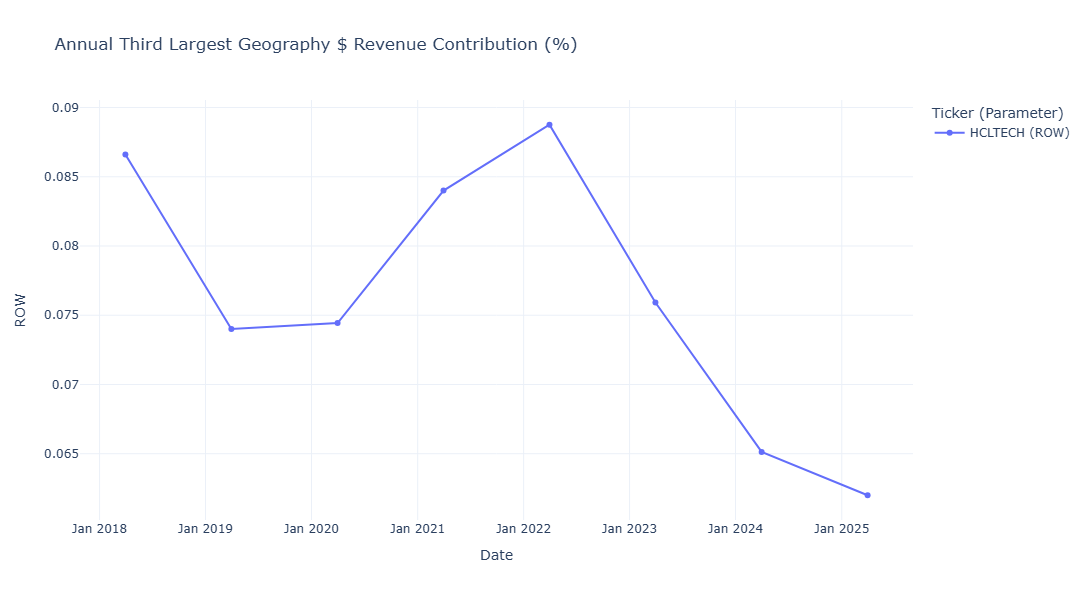

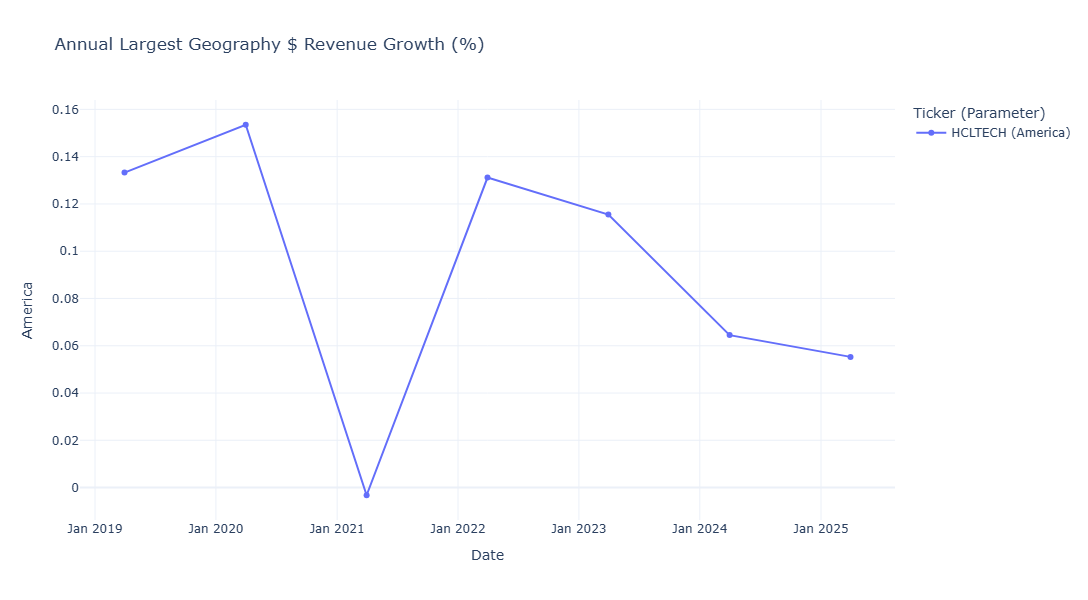

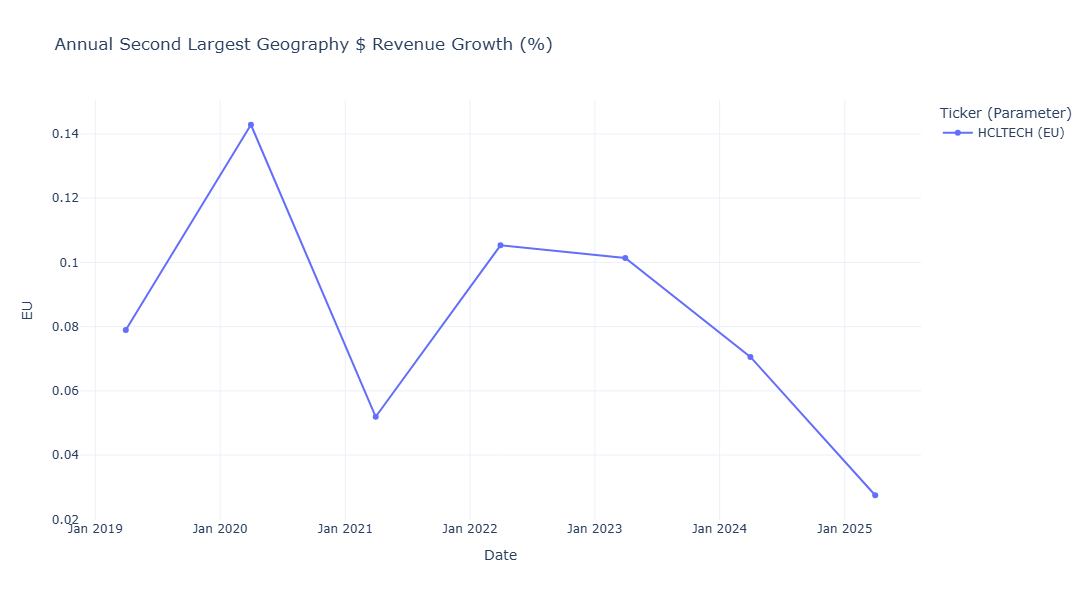

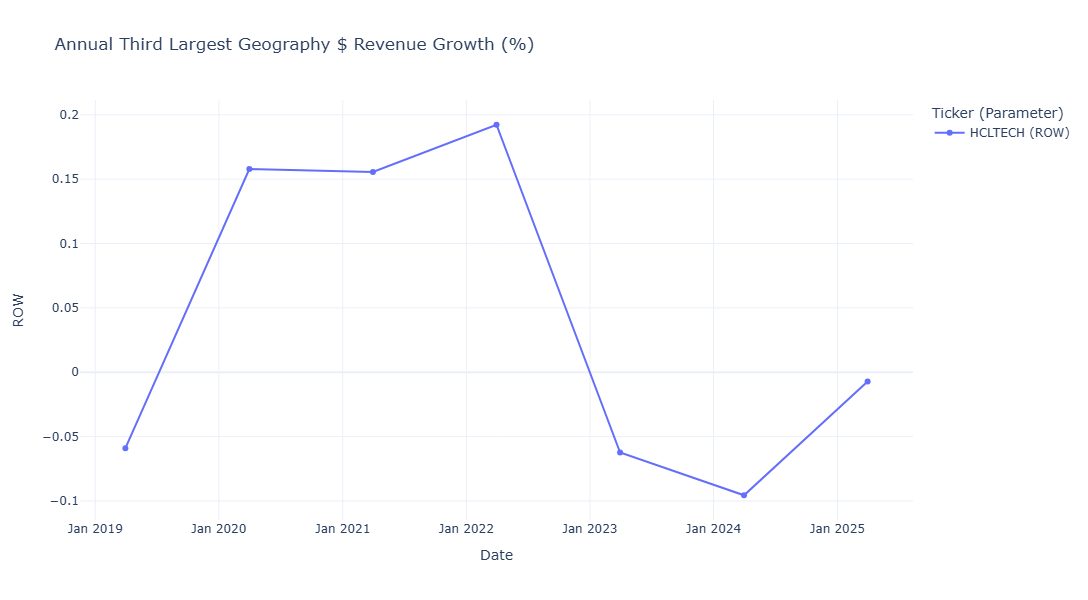

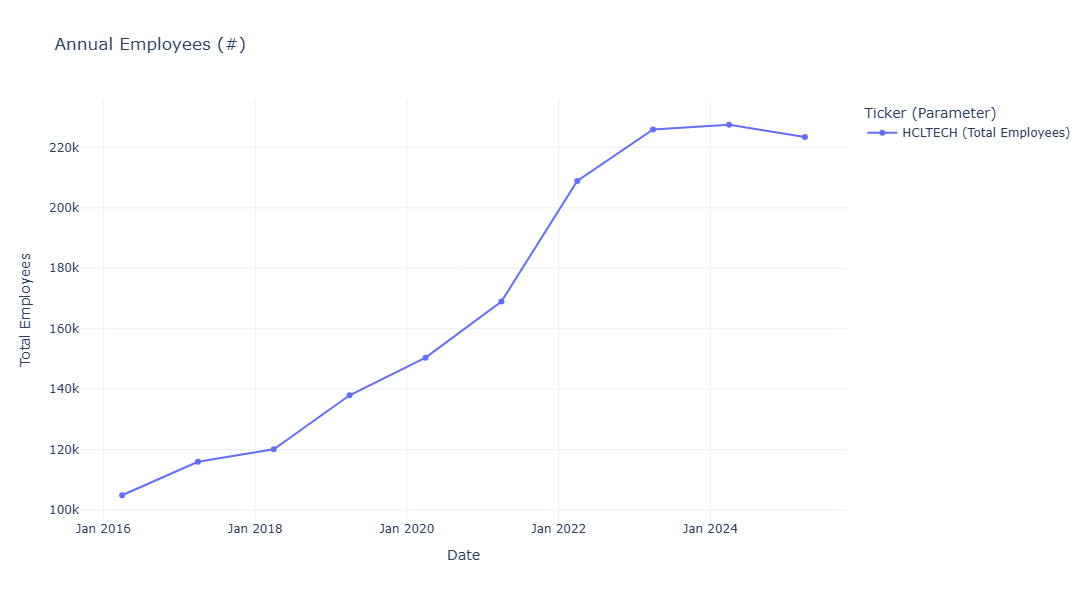

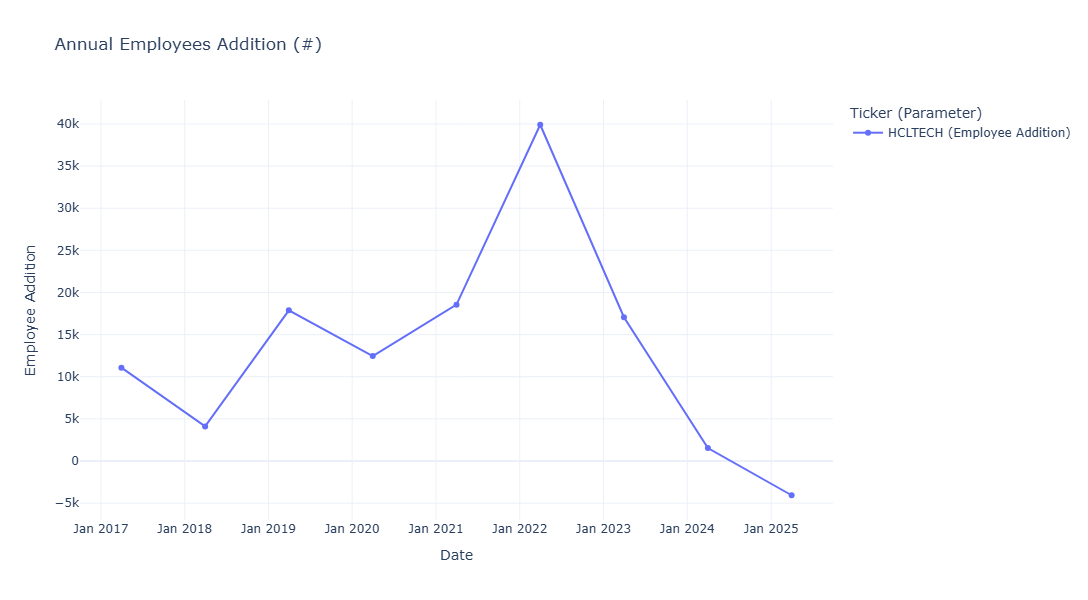

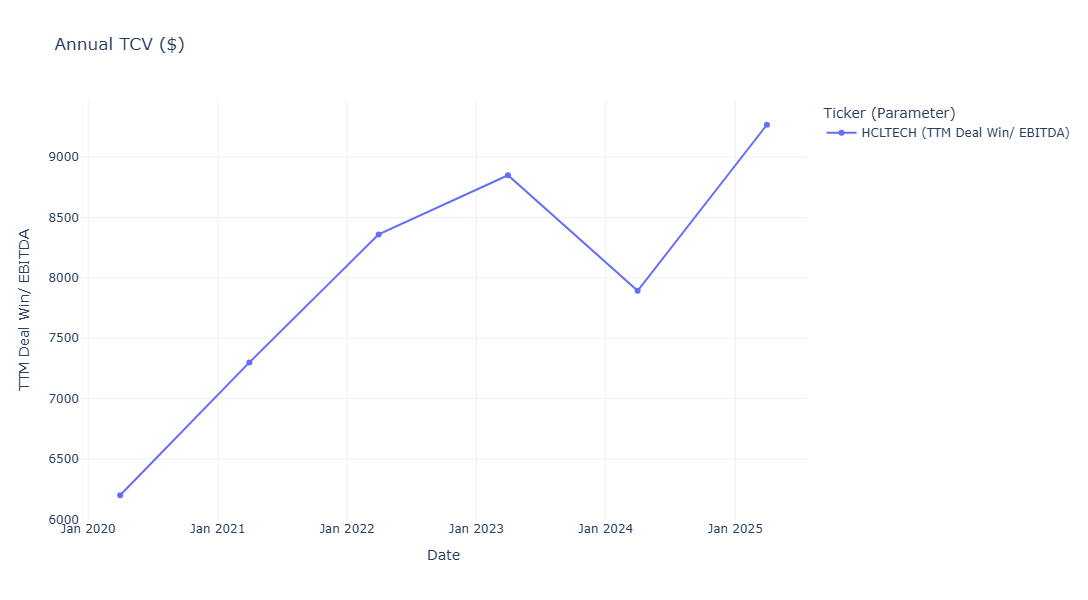

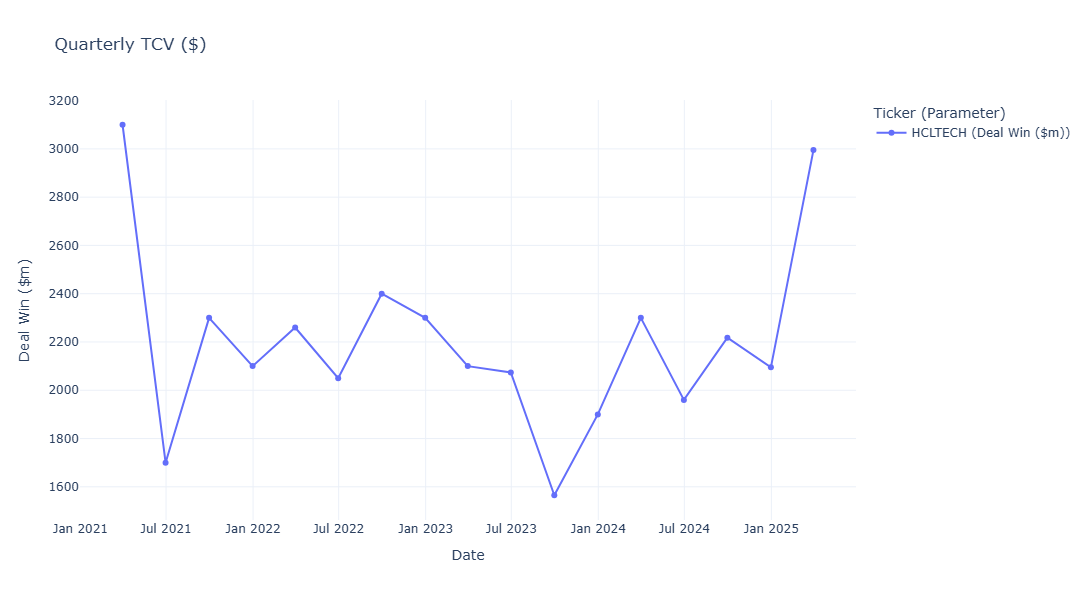

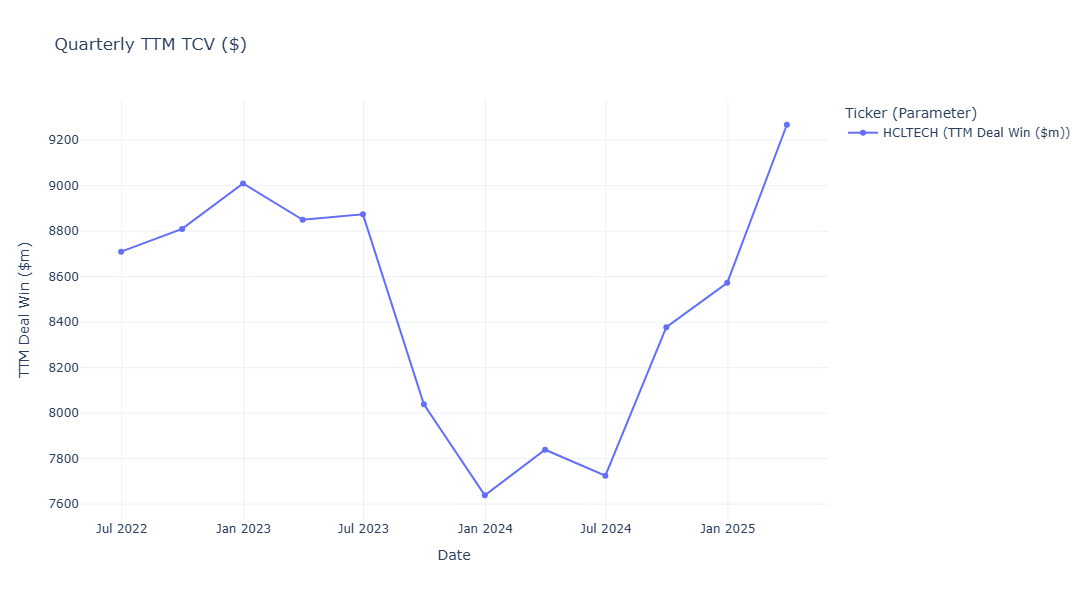

In [11]:
# === Load configuration for chart layout ===
config_file = r"C:\MyDocuments\03Business\11Property\website\ChartForSheet&Row.property"
if not os.path.exists(config_file):  # old location
    config_file = r"C:\MyDocuments\03Business\05ResearchAndAnalysis\StockInvestments\QuarterResultsScreenerExcels\ChartForSheet&Row.property"
config = configparser.ConfigParser(interpolation=None)
config.read(config_file)

# === Manually choose combinations to visualize ===
GeneralCombination = list(range(1, 37))
TechnologyCombination = list(range(101, 150))
GeneralInsuranceCombination = list(range(201, 263))
LifeInsurancesCombination = list(range(301, 353))
BankCombination = list(range(401, 509))
QuarterlyCustomCombination = list(range(71, 76))
AnnualCustomCombination = list(range(81, 87))
SegmentCustomCombination = list(range(91, 101))
CustomCombination = QuarterlyCustomCombination + AnnualCustomCombination # + SegmentCustomCombination

ActiveCombination = TechnologyCombination # GeneralCombination + CustomCombination ## Change Combination

# === Chart rendering ===
for combo in ActiveCombination:
    combo_section = str(combo)

    if combo_section not in config:
        print(f"Combination {combo} not found in config.")
        continue

    sheet_name = config[combo_section]["sheet_name"]
    dateRow = int(config[combo_section]["date_row"])
    parameterRow = int(config[combo_section]["parameter_row"])
    dateColumnStart = config[combo_section]["date_column_start"]
    dateColumnEnd = config[combo_section]["date_column_end"]
    chart_title = config[combo_section]["name"]

    start_col_idx = column_index_from_string(dateColumnStart) - 1
    end_col_idx = column_index_from_string(dateColumnEnd)

    fig = go.Figure()

    for ticker in tickers:
        file_data = file_cache.get(ticker)
        if not file_data:
            continue

        df = file_data["sheets_pd"].get(sheet_name)
        ws = file_data["workbook"][sheet_name]

        if df is None:
            print(f"Sheet {sheet_name} not found in {ticker}")
            continue

        dates = df.iloc[dateRow - 1, start_col_idx:end_col_idx].tolist()
        values = df.iloc[parameterRow - 1, start_col_idx:end_col_idx].tolist()
        parameter_name = df.iloc[parameterRow - 1, 0] if pd.notnull(df.iloc[parameterRow - 1, 0]) else f"Row {parameterRow}"

        cleaned_dates, cleaned_values, tooltips = [], [], []
        for i, (d, v) in enumerate(zip(dates, values)):
            if pd.notnull(d) and pd.notnull(v):
                cell_col = start_col_idx + i + 1
                cell_row = parameterRow
                cell = ws.cell(row=cell_row, column=cell_col)
                num_format = cell.number_format.lower()

                if '%' in num_format:
                    formatted_val = f"{v * 100:.3f}%"
                elif v >= 1000:
                    formatted_val = f"{v:,.0f}"
                else:
                    formatted_val = f"{v:,.1f}"

                cleaned_dates.append(d)
                cleaned_values.append(v)
                tooltips.append(f"{ticker}: {formatted_val}")

        if cleaned_dates:
            fig.add_trace(go.Scatter(
                x=cleaned_dates,
                y=cleaned_values,
                mode='lines+markers',
                name=f"{ticker} ({parameter_name})",
                hoverinfo='text',
                text=tooltips,
                showlegend=True  # <- force legend even for single trace
            ))

    fig.update_layout(
        title=chart_title,
        xaxis_title="Date",
        yaxis_title=parameter_name,
        hovermode="x unified",
        template="plotly_white",
        legend_title="Ticker (Parameter)",
        height=600,
        xaxis=dict(
            tickformat="%b %Y",
            tickmode="auto",
            dtick="M3"
        )
    )

    fig.show()